In [1]:
%pip install optuna


   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ----

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
PROJECT = Path(r"C:\Users\hp\Documents\teliport_prototype")
os.chdir(PROJECT / "notebooks")
sys.path.insert(0, str(PROJECT / "src"))
%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from cmapss_data import load_all, SUBSETS

DATA_DIR = PROJECT / "data" / "raw" / "CMAPSS"
PROC = PROJECT / "data" / "processed"
MODELS = PROJECT / "models"
REPORTS = PROJECT / "reports"
FIG_DIR = REPORTS / "figures"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
data = load_all(DATA_DIR)
print("Working dir:", Path.cwd())

Working dir: C:\Users\hp\Documents\teliport_prototype\notebooks


In [2]:
%%writefile ../src/modeling.py
"""RUL modeling utilities: metrics, engine-level cross-validation, LightGBM training,
seed bagging and calibrated prediction intervals."""
from __future__ import annotations

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import GroupKFold

CRITICAL_RUL = 30          # "act now" zone used for weighting and critical-zone metrics
LGB_PARAMS = dict(n_estimators=500, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
                  random_state=42, n_jobs=-1, verbose=-1)


# ---------------- metrics ----------------
def nasa_score(y_true, y_pred):
    """Official PHM08 score: late predictions (d > 0) are punished harder than early ones."""
    d = np.asarray(y_pred, float) - np.asarray(y_true, float)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_pred, float) - np.asarray(y_true, float)) ** 2)))


def evaluate(y_true, y_pred, critical=CRITICAL_RUL):
    y, p = np.asarray(y_true, float), np.asarray(y_pred, float)
    crit_true, crit_pred = y <= critical, p <= critical
    tp = int((crit_true & crit_pred).sum())
    return {
        "n": len(y),
        "RMSE": round(rmse(y, p), 2),
        "MAE": round(float(np.mean(np.abs(p - y))), 2),
        "NASA_score": round(nasa_score(y, p), 1),
        f"RMSE_RUL<={critical}": round(rmse(y[crit_true], p[crit_true]), 2) if crit_true.any() else np.nan,
        "critical_recall": round(tp / max(int(crit_true.sum()), 1), 3),
        "critical_precision": round(tp / max(int(crit_pred.sum()), 1), 3),
        "late_pred_%": round(100 * float(np.mean(p - y > 10)), 1),   # >10 cycles too optimistic
    }


# ---------------- training helpers ----------------
def make_lgbm(**overrides):
    return lgb.LGBMRegressor(**{**LGB_PARAMS, **overrides})


def sample_weights(rul, critical=CRITICAL_RUL, w=2.0):
    """Mild-imbalance handling: near-failure rows are rarer, so they count double."""
    return np.where(np.asarray(rul) <= critical, w, 1.0)


def val_rows(df, min_cycle=20, max_rul=150):
    """Rows that look like real test engines: some history, and within planning horizon."""
    return df[(df["cycle"] >= min_cycle) & (df["RUL"] <= max_rul)]


def fit_model(df, features, make_model, cap, weighted=True):
    model = make_model()
    y = df["RUL"].clip(upper=cap)
    if weighted:
        model.fit(df[features], y, sample_weight=sample_weights(df["RUL"]))
    else:
        model.fit(df[features], y)
    return model


def predict(model, df, features):
    return np.clip(model.predict(df[features]), 0, None)


def cross_validate(df, features, make_model, cap, weighted=True, n_splits=5):
    """GroupKFold by engine: no engine ever appears in both train and validation."""
    parts = []
    for fold, (a, b) in enumerate(GroupKFold(n_splits=n_splits).split(df, groups=df["unit"])):
        model = fit_model(df.iloc[a], features, make_model, cap, weighted)
        v = val_rows(df.iloc[b])
        parts.append(pd.DataFrame({"unit": v["unit"].to_numpy(), "cycle": v["cycle"].to_numpy(),
                                   "fold": fold, "y_true": v["RUL"].to_numpy(),
                                   "y_pred": predict(model, v, features)}))
    oof = pd.concat(parts, ignore_index=True)
    return evaluate(oof["y_true"], oof["y_pred"]), oof


# ---------------- v2: seed bagging + uncertainty ----------------
class SeedBag:
    """Average of several LightGBM models trained with different random seeds.
    Removes 'lucky seed' variance, so reported results are stable and reproducible."""

    def __init__(self, params=None, seeds=(0, 1, 2, 3, 4)):
        self.params = dict(params or {})
        self.seeds = tuple(seeds)

    def fit(self, X, y, sample_weight=None):
        self.models_ = [make_lgbm(**{**self.params, "random_state": s}).fit(X, y, sample_weight=sample_weight)
                        for s in self.seeds]
        self.feature_names_in_ = list(X.columns)
        return self

    def predict(self, X):
        return np.mean([m.predict(X) for m in self.models_], axis=0)

    def predict_each(self, X):
        return np.vstack([m.predict(X) for m in self.models_])

    @property
    def feature_importances_(self):
        return np.mean([m.booster_.feature_importance("gain") for m in self.models_], axis=0)


class RULUncertainty:
    """Prediction intervals from out-of-fold residuals (split-conformal style), computed
    separately per predicted-RUL band because errors are small near failure, larger far away."""

    def __init__(self, coverage=0.90, edges=(0, 20, 40, 60, 80, 100, np.inf), min_points=30):
        self.coverage = coverage
        self.edges = tuple(edges)
        self.min_points = min_points

    def fit(self, y_true, y_pred):
        y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
        r = y_true - y_pred
        lo_q, hi_q = (1 - self.coverage) / 2, 1 - (1 - self.coverage) / 2
        band = np.digitize(y_pred, self.edges[1:-1])
        g_lo, g_hi = np.quantile(r, lo_q), np.quantile(r, hi_q)
        self.lo_, self.hi_ = [], []
        for b in range(len(self.edges) - 1):
            rb = r[band == b]
            ok = len(rb) >= self.min_points
            self.lo_.append(float(np.quantile(rb, lo_q)) if ok else float(g_lo))
            self.hi_.append(float(np.quantile(rb, hi_q)) if ok else float(g_hi))
        return self

    def interval(self, y_pred):
        y_pred = np.asarray(y_pred, float)
        band = np.digitize(y_pred, self.edges[1:-1])
        lower = np.clip(y_pred + np.asarray(self.lo_)[band], 0, None)
        upper = y_pred + np.asarray(self.hi_)[band]
        return lower, upper

    def table(self):
        labels = [f"{self.edges[i]:.0f}-{self.edges[i+1]:.0f}" for i in range(len(self.edges) - 1)]
        return pd.DataFrame({"pred_RUL_band": labels, "lower_offset": np.round(self.lo_, 1),
                             "upper_offset": np.round(self.hi_, 1)})

Overwriting ../src/modeling.py


In [3]:
%%writefile ../src/training.py
"""ONE training recipe used everywhere: notebooks, MLOps retraining and the end-to-end pipeline."""
from __future__ import annotations

import json
from pathlib import Path

import joblib

from anomaly import HealthMonitor
from features import CMAPSSPreprocessor, DEFAULT_RUL_CAP
from modeling import RULUncertainty, SeedBag, cross_validate, fit_model, make_lgbm

DEFAULT_MONITOR = {"method": "mahalanobis", "quantile": 0.99, "persistence": 5}


def load_config(models_dir, filename, fd, default):
    path = Path(models_dir) / filename if models_dir else None
    if path and path.exists():
        return json.loads(path.read_text()).get(fd, default)
    return default


def train_pipeline(fd, train_raw, models_dir=None, params=None, monitor_cfg=None,
                   cap=DEFAULT_RUL_CAP, seeds=(0, 1, 2, 3, 4), calib_folds=3):
    """train_raw: run-to-failure history with an RUL column. Returns every fitted component."""
    params = params if params is not None else load_config(models_dir, "best_params.json", fd, {})
    monitor_cfg = monitor_cfg or load_config(models_dir, "monitor_config.json", fd, DEFAULT_MONITOR)

    prep = CMAPSSPreprocessor.for_subset(fd)
    tr = prep.fit_transform(train_raw)
    F = prep.feature_names_

    _, oof = cross_validate(tr, F, lambda: make_lgbm(**params), cap, n_splits=calib_folds)
    unc = RULUncertainty().fit(oof["y_true"], oof["y_pred"])          # calibrated on unseen engines
    model = fit_model(tr, F, lambda: SeedBag(params, seeds), cap, weighted=True)
    hm = HealthMonitor(**monitor_cfg).fit(tr, prep.sensors)
    return {"prep": prep, "model": model, "unc": unc, "hm": hm, "features": F,
            "params": params, "monitor_cfg": monitor_cfg, "train_features": tr}


def save_pipeline(p, fd, models_dir):
    models_dir = Path(models_dir)
    models_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump(p["prep"], models_dir / f"preprocessor_{fd}.joblib")
    joblib.dump(p["model"], models_dir / f"lgbm_{fd}.joblib")
    joblib.dump(p["unc"], models_dir / f"uncertainty_{fd}.joblib")
    joblib.dump(p["hm"], models_dir / f"health_monitor_{fd}.joblib")

Writing ../src/training.py


In [4]:
import optuna
from modeling import cross_validate, make_lgbm, LGB_PARAMS
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS, TIMEOUT = 30, 300            # per subset
TUNED = ["n_estimators", "learning_rate", "num_leaves", "min_child_samples", "colsample_bytree", "reg_lambda"]
best, rows = {}, []
for fd in SUBSETS:
    tr = pd.read_pickle(PROC / f"train_{fd}.pkl")
    F = joblib.load(MODELS / f"preprocessor_{fd}.joblib").feature_names_

    def objective(trial):
        p = dict(n_estimators=trial.suggest_int("n_estimators", 200, 1000, step=100),
                 learning_rate=trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
                 num_leaves=trial.suggest_int("num_leaves", 8, 64, log=True),
                 min_child_samples=trial.suggest_int("min_child_samples", 20, 200, log=True),
                 colsample_bytree=trial.suggest_float("colsample_bytree", 0.2, 0.8),
                 reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True))
        m, _ = cross_validate(tr, F, lambda: make_lgbm(**p), cap=125, n_splits=3)
        return m["RMSE"]

    t0 = time.time()
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.enqueue_trial({k: LGB_PARAMS[k] for k in TUNED})        # trial 0 = old default settings
    study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT)
    best[fd] = study.best_params
    rows.append({"subset": fd, "trials": len(study.trials),
                 "cv_RMSE_default": round(study.trials[0].value, 2),
                 "cv_RMSE_tuned": round(study.best_value, 2),
                 "minutes": round((time.time() - t0) / 60, 1)})
    print(rows[-1], flush=True)

(MODELS / "best_params.json").write_text(json.dumps(best, indent=2))
pd.DataFrame(rows).set_index("subset")

{'subset': 'FD001', 'trials': 30, 'cv_RMSE_default': 13.13, 'cv_RMSE_tuned': 12.75, 'minutes': 1.6}
{'subset': 'FD002', 'trials': 30, 'cv_RMSE_default': 13.7, 'cv_RMSE_tuned': 13.51, 'minutes': 3.2}
{'subset': 'FD003', 'trials': 30, 'cv_RMSE_default': 12.8, 'cv_RMSE_tuned': 12.54, 'minutes': 3.1}
{'subset': 'FD004', 'trials': 29, 'cv_RMSE_default': 14.93, 'cv_RMSE_tuned': 14.91, 'minutes': 5.0}


,trials,cv_RMSE_default,cv_RMSE_tuned,minutes
subset,,,,
FD001,30,13.13,12.75,1.6
FD002,30,13.70,13.51,3.2
FD003,30,12.80,12.54,3.1
FD004,29,14.93,14.91,5.0


In [5]:
from sklearn.ensemble import ExtraTreesRegressor
from modeling import rmse

tr = pd.read_pickle(PROC / "train_FD001.pkl")
F = joblib.load(MODELS / "preprocessor_FD001.joblib").feature_names_
_, oof_lgb = cross_validate(tr, F, lambda: make_lgbm(**best["FD001"]), cap=125, n_splits=3)
_, oof_et = cross_validate(tr, F, lambda: ExtraTreesRegressor(n_estimators=200, min_samples_leaf=5,
                                                              max_features=0.3, n_jobs=-1, random_state=0),
                           cap=125, n_splits=3)
assert (oof_lgb[["unit", "cycle"]].to_numpy() == oof_et[["unit", "cycle"]].to_numpy()).all()
y, a, b = oof_lgb["y_true"].to_numpy(), oof_lgb["y_pred"].to_numpy(), oof_et["y_pred"].to_numpy()
rows = [{"model": "LightGBM (tuned)", "cv_RMSE": rmse(y, a)}, {"model": "ExtraTrees", "cv_RMSE": rmse(y, b)}]
rows += [{"model": f"blend {w:.0%} LGBM + {1-w:.0%} ET", "cv_RMSE": rmse(y, w * a + (1 - w) * b)}
         for w in (0.5, 0.7, 0.85)]
ens = pd.DataFrame(rows).round(2).set_index("model")
ens.to_csv(REPORTS / "ensemble_check_fd001.csv")
ens

,cv_RMSE
model,
LightGBM (tuned),12.75
ExtraTrees,14.52
blend 50% LGBM + 50% ET,13.32
blend 70% LGBM + 30% ET,13.01
blend 85% LGBM + 15% ET,12.85


In [6]:
from sklearn.model_selection import GroupKFold
from anomaly import HealthMonitor, detection_report

grid_rows, monitor_cfg = [], {}
for fd in SUBSETS:
    tr = pd.read_pickle(PROC / f"train_{fd}.pkl")
    S = joblib.load(MODELS / f"preprocessor_{fd}.joblib").sensors
    folds = list(GroupKFold(n_splits=4).split(tr, groups=tr["unit"]))
    for q in (0.99, 0.995, 0.999):
        fitted = [HealthMonitor(quantile=q).fit(tr.iloc[a], S) for a, _ in folds]
        for k in (3, 5, 8):
            parts = []
            for hm, (_, b) in zip(fitted, folds):
                hm.persistence = k
                parts.append(hm.transform(tr.iloc[b]))
            r = detection_report(tr, pd.concat(parts).loc[tr.index])
            grid_rows.append({"subset": fd, "quantile": q, "persistence": k, **r})

grid = pd.DataFrame(grid_rows)
for fd, g in grid.groupby("subset"):
    ok = g[g["detected_before_RUL30_%"] >= 98.0]
    if len(ok):
        pick = ok.sort_values(["false_alarm_rate_%", "median_lead_time_cycles"], ascending=[True, False]).iloc[0]
    else:
        pick = g.sort_values("detected_before_RUL30_%", ascending=False).iloc[0]
    monitor_cfg[fd] = {"method": "mahalanobis", "quantile": float(pick["quantile"]),
                       "persistence": int(pick["persistence"])}

(MODELS / "monitor_config.json").write_text(json.dumps(monitor_cfg, indent=2))
grid.to_csv(REPORTS / "anomaly_threshold_grid.csv", index=False)
chosen = pd.concat([grid[(grid.subset == fd) & (grid["quantile"] == c["quantile"]) &
                         (grid.persistence == c["persistence"])] for fd, c in monitor_cfg.items()])
chosen.set_index("subset")

,quantile,persistence,engines,false_alarm_rate_%,engines_with_early_alarm_%,detected_before_failure_%,detected_before_RUL30_%,median_lead_time_cycles
subset,,,,,,,,
FD001,0.999,5,100,0.24,2.0,100.0,98.0,64.5
FD002,0.995,3,260,0.42,4.6,100.0,98.8,65.0
FD003,0.999,8,100,0.11,1.0,100.0,99.0,56.0
FD004,0.990,5,249,0.96,4.8,100.0,98.0,64.0


In [7]:
from features import last_cycle
from modeling import evaluate, rmse
from training import train_pipeline, save_pipeline

old = pd.read_csv(REPORTS / "rul_test_results_lgbm.csv", index_col="subset")
rows, unc_tables = [], {}
for fd in SUBSETS:
    t0 = time.time()
    train, test, rul = data[fd]
    p = train_pipeline(fd, train, models_dir=MODELS)          # tuned params + monitor config from JSON
    save_pipeline(p, fd, MODELS)

    te = last_cycle(p["prep"].transform(test)).merge(rul[["unit", "RUL"]], on="unit")
    X, y = te[p["features"]], te["RUL"].to_numpy()
    pred = np.clip(p["model"].predict(X), 0, None)
    lower, upper = p["unc"].interval(pred)
    single = [rmse(y, np.clip(s, 0, None)) for s in p["model"].predict_each(X)]
    m = evaluate(y, pred)
    zone = y <= 125
    rows.append({"subset": fd, "old_RMSE": old.loc[fd, "RMSE"], "new_RMSE": m["RMSE"],
                 "single_seed_range": f"{min(single):.2f}-{max(single):.2f}",
                 "new_NASA_score": m["NASA_score"], "RMSE_RUL<=30": m["RMSE_RUL<=30"],
                 "RMSE_trueRUL<=125": round(rmse(y[zone], pred[zone]), 2),
                 "interval_coverage_%": round(100 * np.mean((y >= lower) & (y <= upper)), 1),
                 "coverage_trueRUL<=125_%": round(100 * np.mean(((y >= lower) & (y <= upper))[zone]), 1),
                 "lower_bound_safe_%": round(100 * np.mean(y >= lower), 1),
                 "secs": round(time.time() - t0)})
    unc_tables[fd] = p["unc"].table()
    print(fd, "done", flush=True)

v2 = pd.DataFrame(rows).set_index("subset")
v2.to_csv(REPORTS / "rul_test_results_v2.csv")
v2.T

FD001 done
FD002 done
FD003 done
FD004 done


subset,FD001,FD002,FD003,FD004
old_RMSE,11.34,23.2,12.25,23.83
new_RMSE,11.48,23.27,12.26,23.93
single_seed_range,11.47-11.68,23.21-23.41,12.18-12.40,23.92-23.97
new_NASA_score,187.1,4870.6,266.2,3382.7
RMSE_RUL<=30,2.85,2.73,2.53,4.27
RMSE_trueRUL<=125,9.91,11.29,10.49,11.97
interval_coverage_%,93.0,78.4,95.0,78.6
coverage_trueRUL<=125_%,93.3,89.6,94.1,93.4
lower_bound_safe_%,96.0,96.1,96.0,96.4
secs,11,23,17,28


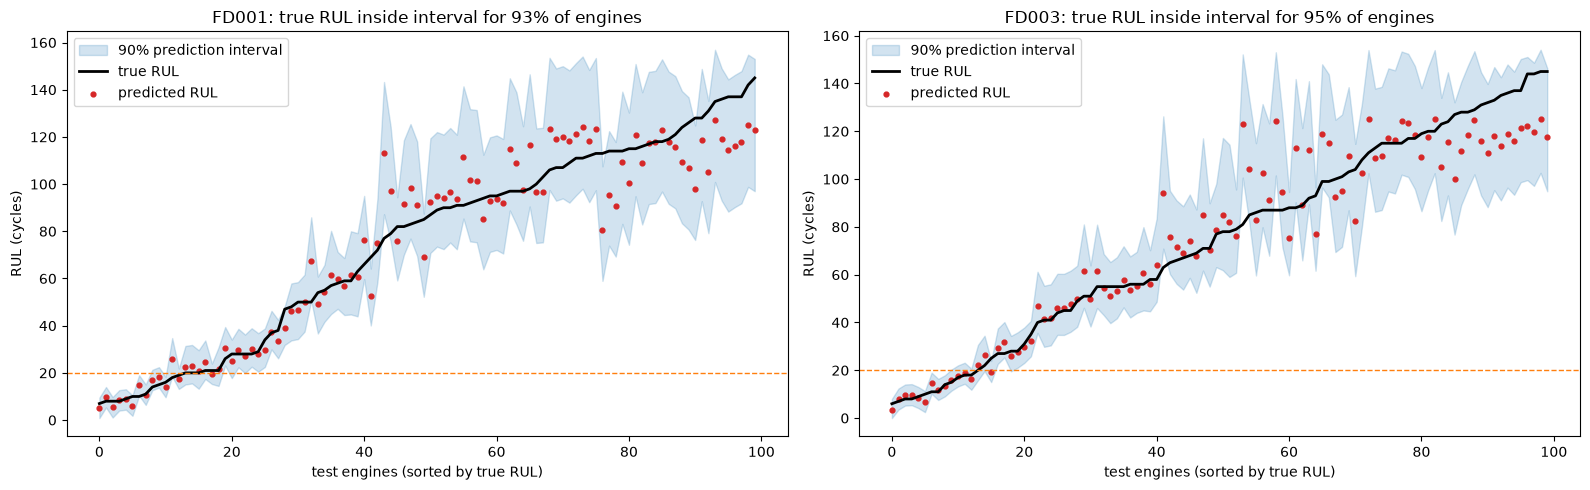

  pred_RUL_band  lower_offset  upper_offset
0          0-20          -4.3           4.3
1         20-40          -7.3           9.0
2         40-60         -12.4          11.7
3         60-80         -16.7          18.6
4        80-100         -21.5          27.0
5       100-inf         -26.1          30.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, fd in zip(axes, ["FD001", "FD003"]):
    _, test, rul = data[fd]
    prep = joblib.load(MODELS / f"preprocessor_{fd}.joblib")
    model = joblib.load(MODELS / f"lgbm_{fd}.joblib")
    unc = joblib.load(MODELS / f"uncertainty_{fd}.joblib")
    te = (last_cycle(prep.transform(test)).merge(rul[["unit", "RUL"]], on="unit")
          .sort_values("RUL").reset_index(drop=True))
    p = np.clip(model.predict(te[prep.feature_names_]), 0, None)
    lo, hi = unc.interval(p)
    inside = (te["RUL"] >= lo) & (te["RUL"] <= hi)
    ax.fill_between(te.index, lo, hi, color="tab:blue", alpha=0.2, label="90% prediction interval")
    ax.plot(te.index, te["RUL"], color="k", lw=2, label="true RUL")
    ax.scatter(te.index, p, s=12, color="tab:red", label="predicted RUL")
    ax.axhline(20, ls="--", c="tab:orange", lw=1)
    ax.set_title(f"{fd}: true RUL inside interval for {100 * inside.mean():.0f}% of engines")
    ax.set_xlabel("test engines (sorted by true RUL)"); ax.set_ylabel("RUL (cycles)"); ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG_DIR / "09_rul_uncertainty.png", bbox_inches="tight")
plt.show()
print(unc_tables["FD001"])